# 11. Итоговое сравнение многоклассовой классификации на test

**Задача:** оценить способность классического ML и Deep Learning определять четыре типа банковских новостей на одной отложенной выборке.

Модели зафиксированы до финального тестирования:

- **Logistic Regression**: `LogisticRegression_text_balanced`, выбранная по validation Macro F1.
- **mDeBERTa**: `text_standard`, seed **42**, выбранная в первоначальном многоклассовом эксперименте. Последующие seed 123/2026 использовались только для проверки устойчивости.

Обе модели уже обучены. Этот ноутбук **не обучает модели и не подбирает параметры по test**: он воспроизводит метрики по сохранённым предсказаниям для 751 тестовой новости. Исходный датасет не изменён.

## 1. Загрузка и верификация источников

Проверка включает SHA-256 датасета, состав test, уникальность `sample_id`, истинные метки и совпадение пересчитанных F1 и матриц ошибок с сохранёнными результатами.

In [2]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             accuracy_score, classification_report, ConfusionMatrixDisplay)

LABELS = ['no_risk', 'cyber_risk', 'operational_risk', 'regulatory_risk']
LABELS_RU = ['Без риска', 'Киберриск', 'Операционный', 'Регуляторный']
SHA = '52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3'
ROOT = Path.cwd()
if not (ROOT / 'data/bank_risk_dataset.csv').is_file():
    options = [x for x in ROOT.iterdir() if x.is_dir() and (x / 'data/bank_risk_dataset.csv').is_file()]
    if not options:
        raise FileNotFoundError('Рабочий каталог должен содержать data/bank_risk_dataset.csv.')
    ROOT = options[0]
source = ROOT / 'data/bank_risk_dataset.csv'
assert hashlib.sha256(source.read_bytes()).hexdigest() == SHA
truth = pd.read_csv(source).query("split == 'test'")[['sample_id', 'risk_type_4cls']].copy()
assert len(truth) == 751 and truth.sample_id.is_unique

sources = {
  'Logistic Regression': ROOT / 'results/multiclass/final_test/baseline',
  'mDeBERTa (seed 42)': ROOT / 'results/multiclass/final_test/dl',
}
metrics, aligned = {}, {}
for name, folder in sources.items():
    obj = json.loads((folder / 'test_metrics.json').read_text(encoding='utf8'))
    pred = pd.read_csv(folder / 'test_predictions.csv')
    assert obj['split'] == 'test' and obj['dataset_sha256'] == SHA and obj['n_samples'] == 751
    assert pred.sample_id.is_unique and len(pred) == 751
    assert set(pred.sample_id) == set(truth.sample_id)
    joined = truth.merge(pred, on='sample_id', validate='one_to_one').sort_values('sample_id')
    assert (joined.risk_type_4cls == joined['true']).all()
    assert set(joined.prediction).issubset(LABELS)
    calc_f1 = f1_score(joined['true'], joined.prediction, labels=LABELS, average='macro', zero_division=0)
    calc_cm = confusion_matrix(joined['true'], joined.prediction, labels=LABELS)
    assert np.isclose(calc_f1, obj['macro_f1'], rtol=0, atol=1e-12)
    assert np.array_equal(calc_cm, np.asarray(obj['confusion_matrix']))
    metrics[name] = obj
    aligned[name] = joined
    print(f'{name}: {len(joined)} test-примеров, Macro F1 = {calc_f1:.4f} — проверено')

Logistic Regression: 751 test-примеров, Macro F1 = 0.8206 — проверено
mDeBERTa (seed 42): 751 test-примеров, Macro F1 = 0.7329 — проверено


## 2. Основные метрики на validation и test

Macro F1 — среднее арифметическое F1 по всем четырём классам; оно не позволяет распространённому классу `no_risk` скрыть проблемы на редких категориях. `Risk Macro F1` усредняет только три типа риска.

Сравнение на validation приведено для уже выбранных моделей. Test не применялся для их выбора.

,Validation Macro F1,Test Macro F1,Test Risk Macro F1,Test Macro Precision,Test Macro Recall,Test Accuracy
Модель,,,,,,
Logistic Regression,0.7446,0.8206,0.7639,0.8268,0.8281,0.9827
mDeBERTa (seed 42),0.7500,0.7329,0.6481,0.7670,0.7108,0.9734


Разница DL − baseline (test Macro F1): -0.0877


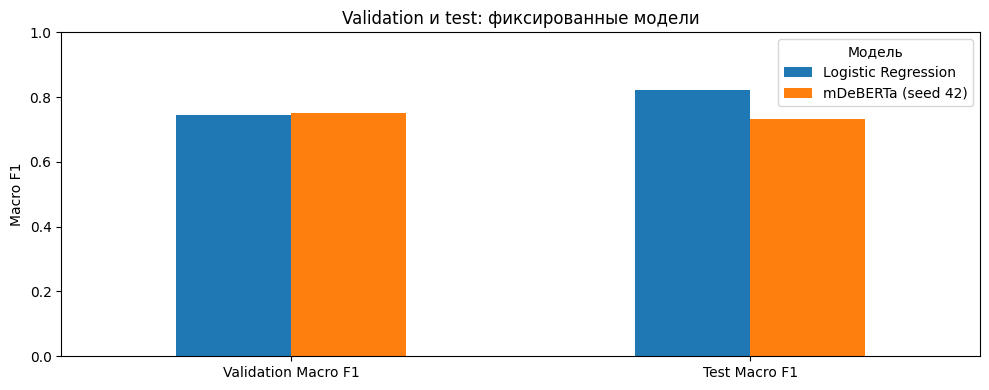

In [3]:
validation = {'Logistic Regression': 0.7446479542288609,
              'mDeBERTa (seed 42)': 0.7500282109800939}
rows = []
for name, m in metrics.items():
    rows.append({'Модель': name, 'Validation Macro F1': validation[name],
                 'Test Macro F1': m['macro_f1'], 'Test Risk Macro F1': m['risk_macro_f1'],
                 'Test Macro Precision': m['macro_precision'],
                 'Test Macro Recall': m['macro_recall'], 'Test Accuracy': m['accuracy']})
summary = pd.DataFrame(rows)
display(summary.set_index('Модель').round(4))
print('Разница DL − baseline (test Macro F1):',
      f"{metrics['mDeBERTa (seed 42)']['macro_f1'] - metrics['Logistic Regression']['macro_f1']:+.4f}")
ax = summary.set_index('Модель')[['Validation Macro F1', 'Test Macro F1']].T.plot.bar(rot=0, figsize=(10, 4))
ax.set_ylim(0, 1); ax.set_ylabel('Macro F1'); ax.set_title('Validation и test: фиксированные модели')
plt.tight_layout(); plt.show()

## 3. Качество распознавания каждого класса

F1 рассчитан отдельно для каждого класса. Регуляторный риск представлен всего четырьмя тестовыми новостями (**4 примера**), поэтому его оценка особенно чувствительна к отдельным ошибкам.

,Поддержка (test),Logistic Regression F1,mDeBERTa F1,Разница DL − baseline
Класс,,,,
Без риска,713,0.9909,0.9874,-0.0035
Киберриск,17,0.8485,0.6857,-0.1628
Операционный,17,0.8718,0.7586,-0.1132
Регуляторный,4,0.5714,0.5000,-0.0714


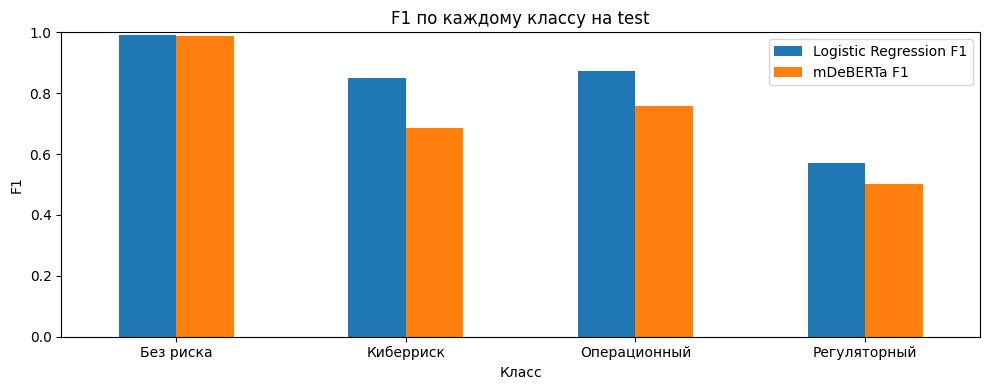

In [4]:
per_class = pd.DataFrame({
    'Класс': LABELS_RU,
    'Поддержка (test)': [int((truth.risk_type_4cls == k).sum()) for k in LABELS],
    'Logistic Regression F1': [metrics['Logistic Regression']['f1_' + k] for k in LABELS],
    'mDeBERTa F1': [metrics['mDeBERTa (seed 42)']['f1_' + k] for k in LABELS],
})
per_class['Разница DL − baseline'] = per_class['mDeBERTa F1'] - per_class['Logistic Regression F1']
display(per_class.set_index('Класс').round(4))
ax = per_class.set_index('Класс')[['Logistic Regression F1', 'mDeBERTa F1']].plot.bar(rot=0, figsize=(10, 4))
ax.set_ylim(0, 1); ax.set_ylabel('F1'); ax.set_title('F1 по каждому классу на test')
plt.tight_layout(); plt.show()

## 4. Матрицы ошибок

Строки — истинные классы, столбцы — предсказанные. Диагональ — правильные решения. Здесь видны и ложные сигналы, и пропущенные риски, и ошибки определения категории.

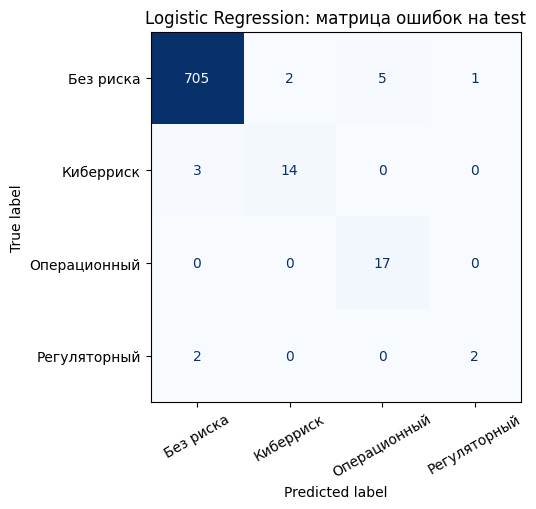

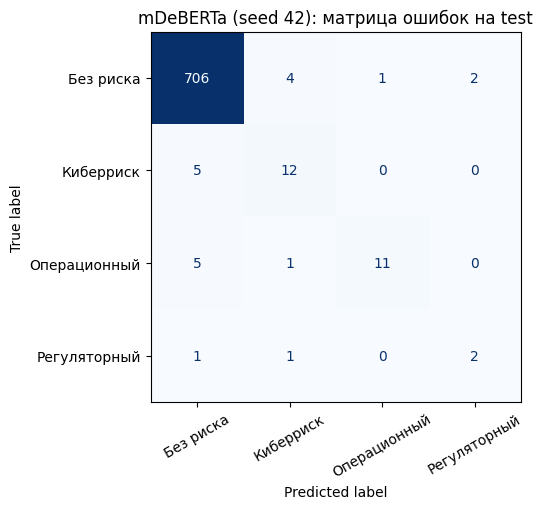

In [5]:
for name, df in aligned.items():
    cm = confusion_matrix(df['true'], df.prediction, labels=LABELS)
    fig, ax = plt.subplots(figsize=(6.7, 5.2))
    disp = ConfusionMatrixDisplay(cm, display_labels=LABELS_RU)
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=30)
    ax.set_title(name + ': матрица ошибок на test')
    plt.tight_layout(); plt.show()

## 5. Сопоставление ошибок на одних и тех же новостях

Парное сравнение на 751 примере показывает общие и различающиеся ошибки моделей. Это описательный разбор ошибок, а не основание изменить выбор модели.

In [6]:
a = aligned['Logistic Regression'][['sample_id','true','prediction']].rename(columns={'prediction':'baseline_prediction'})
b = aligned['mDeBERTa (seed 42)'][['sample_id','prediction']].rename(columns={'prediction':'dl_prediction'})
paired = a.merge(b, on='sample_id', validate='one_to_one')
paired['baseline_correct'] = paired['true'] == paired['baseline_prediction']
paired['dl_correct'] = paired['true'] == paired['dl_prediction']
both = int((paired.baseline_correct & paired.dl_correct).sum())
base_only = int((paired.baseline_correct & ~paired.dl_correct).sum())
dl_only = int((~paired.baseline_correct & paired.dl_correct).sum())
neither = int((~paired.baseline_correct & ~paired.dl_correct).sum())
display(pd.DataFrame({'Категория': ['Обе верны','Только baseline верна','Только mDeBERTa верна','Обе ошиблись'],
                      'Число новостей': [both,base_only,dl_only,neither]}).set_index('Категория'))

for name,pred_col in [('Logistic Regression','baseline_prediction'),('mDeBERTa','dl_prediction')]:
    actual_risk = paired['true'] != 'no_risk'
    predicted_risk = paired[pred_col] != 'no_risk'
    false_alerts = int((~actual_risk & predicted_risk).sum())
    missed_risks = int((actual_risk & ~predicted_risk).sum())
    wrong_risk_type = int((actual_risk & predicted_risk & (paired['true']!=paired[pred_col])).sum())
    print(f'{name}: ложные тревоги={false_alerts}, пропущенные риски={missed_risks}, ошибочный тип риска={wrong_risk_type}')

,Число новостей
Категория,
Обе верны,725
Только baseline верна,13
Только mDeBERTa верна,6
Обе ошиблись,7


Logistic Regression: ложные тревоги=8, пропущенные риски=5, ошибочный тип риска=0
mDeBERTa: ложные тревоги=7, пропущенные риски=11, ошибочный тип риска=2


## 6. Итог и ограничения

В дополнительной многоклассовой задаче предпочтительной признана Logistic Regression: test Macro F1 = 0,8206 против 0,7329 у mDeBERTa seed 42. На validation результаты были близки: 0,7446 и 0,7500 соответственно. Усложнение архитектуры в данном исследовании не улучшило итоговое качество определения категории риска.

Этот результат дополняет основную бинарную задачу. В ней mDeBERTa предпочтительна для сценария с акцентом на Precision предупреждений, а Logistic Regression выше по test F1 и Recall. Метрики разных постановок напрямую не сравниваются.

Ограничения: дисбаланс классов, четыре регуляторных примера на test, зависимость validation-результатов от seed, возможные смысловые повторы и историческое использование тестовой части в бинарном исследовании. Зафиксированные модели и seed после просмотра test не заменялись. Качество на новом потоке новостей требует отдельной проверки.

In [7]:
output = ROOT / 'results/multiclass/final_test'
summary.to_csv(output / 'final_comparison.csv', index=False)
per_class.to_csv(output / 'final_per_class.csv', index=False)
paired.to_csv(output / 'final_paired_predictions.csv', index=False)
print('Итоговые таблицы сохранены в', output)

Итоговые таблицы сохранены в D:\bank_risk_diploma_final_multiclass_2026_10_25\_review_execution\results\multiclass\final_test
